# ДЗ №2. Задание 1
### Выполнил: Лёвин В.А.
### Группа: ИУ6-54Б

Станции и городские зоны.


## Подготовка

Читаем CSV как строки. Координаты преобразуем в числа при выделении отправлений и прибытий.

Читаем границы зон и создаём справочник с уникальными кодами.

In [1]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from pyspark import SparkConf
from pyspark.sql import SparkSession, functions as F

conf = SparkConf().setMaster("local[2]").setAppName("HW2-Stations")
spark = SparkSession.builder.config(conf=conf).getOrCreate()

trips = (
    spark.read.csv("../*citibike-tripdata*.csv", header=True)
    .select("start_station_id", "start_station_name", "start_lat", "start_lng",
            "end_station_id", "end_station_name", "end_lat", "end_lng")
    .cache()
)

zones_map = gpd.read_file("../data/nyc_zones.geojson")
zone_shapes = list(zip(zones_map["locationid"], zones_map.geometry))
zones = (
    spark.createDataFrame(zones_map[["locationid", "zone", "borough"]])
    .toDF("zone_id", "zone_name", "borough")
    .dropDuplicates(["zone_id"])
)

26/11/18 20:00:45 WARN Utils: Your hostname, MacBook-Air-mac-4.local resolves to a loopback address: 127.0.0.1; using 192.168.0.116 instead (on interface en0)
26/11/18 20:00:45 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/18 20:00:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Количество отправлений и прибытий по станциям

Объединяем отправления и прибытия, суммируем по ID станции

In [2]:
starts = trips.selectExpr(
    "trim(start_station_id) as station_id", "start_station_name as station_name",
    "cast(start_lat as double) as latitude", "cast(start_lng as double) as longitude",
    "1 as starts", "0 as ends"
)
ends = trips.selectExpr(
    "trim(end_station_id) as station_id", "end_station_name as station_name",
    "cast(end_lat as double) as latitude", "cast(end_lng as double) as longitude",
    "0 as starts", "1 as ends"
)
events = starts.unionByName(ends)
valid_coordinates = F.expr("""
    latitude BETWEEN -90 AND 90
    AND longitude BETWEEN -180 AND 180
    AND latitude != 0
    AND longitude != 0
""")

station_counts = (
    events.filter("station_id != ''")
    .groupBy("station_id")
    .agg(
        F.first("station_name", ignorenulls=True).alias("station_name"),
        F.sum("starts").alias("starts"), F.sum("ends").alias("ends"),
        F.round(F.avg(F.when(valid_coordinates, F.col("latitude"))), 6).alias("latitude"),
        F.round(F.avg(F.when(valid_coordinates, F.col("longitude"))), 6).alias("longitude")
    )
    .cache()
)

station_table = station_counts.select("station_id", "station_name", "starts", "ends")
station_table.orderBy(F.desc("starts"), "station_id").show(10)

+----------+--------------------+------+-----+
|station_id|        station_name|starts| ends|
+----------+--------------------+------+-----+
|   6140.05|     W 21 St & 6 Ave| 14539|14567|
|   6233.04|Pier 61 at Chelse...| 13480|13505|
|   6492.08|     9 Ave & W 33 St| 12003|12033|
|   6331.01|     W 31 St & 7 Ave| 11683|11733|
|   5980.10|  E 17 St & Broadway| 11505|11582|
|   6098.10|  Broadway & E 21 St| 11414| 3097|
|   5788.13|Lafayette St & E ...| 11281|11373|
|   6912.01|7 Ave & Central P...| 10958|10892|
|   5905.14|University Pl & E...| 10957|11042|
|   5905.12|  Broadway & E 14 St| 10907|10975|
+----------+--------------------+------+-----+
only showing top 10 rows



## 2. Сопоставление станций с зонами и суммы по зонам

Для станции выбираем первую зону, содержащую точку `(долгота, широта)`. Суммируем отправления и прибытия по коду зоны. Станции вне полигонов в суммы зон не входят.

В выводе — 10 соответствий станции и зоны, затем 10 зон с суммами отправлений и прибытий.

In [3]:
def find_zone(longitude, latitude):
    if longitude is None or latitude is None:
        return None
    point = Point(longitude, latitude)
    for zone_id, polygon in zone_shapes:
        if polygon.covers(point):
            return zone_id
    return None

zone_for_point = F.udf(find_zone, "string")
stations = (
    station_counts.withColumn("zone_id", zone_for_point("longitude", "latitude"))
    .join(zones, "zone_id", "left")
)

zone_counts = stations.groupBy("zone_id").sum("starts", "ends")
zone_counts = zone_counts.toDF("zone_id", "starts", "ends")
zone_counts = zones.join(zone_counts, "zone_id", "left").fillna(0).cache()

stations.select("station_id", "station_name", "zone_id", "zone_name").show(10)
zone_counts.show(10)

+----------+--------------------+-------+--------------------+
|station_id|        station_name|zone_id|           zone_name|
+----------+--------------------+-------+--------------------+
|   5902.07|Eagle St & Manhat...|    112|          Greenpoint|
|   7790.04|Lenox Ave & W 133 St|     42|Central Harlem North|
|   7722.06|E 141 St & St Ann...|    168|Mott Haven/Port M...|
|   3394.03|McDonald Ave & Va...|    111| Green-Wood Cemetery|
|   4157.10|Bergen St & Vande...|    189|    Prospect Heights|
|   4677.06|Montague St & Cli...|     33|    Brooklyn Heights|
|   6542.05|      99 St & 35 Ave|    173|        North Corona|
|   5922.08| Bank St & Hudson St|    158|Meatpacking/West ...|
|   8049.05|Edgecombe Ave & W...|    116|    Hamilton Heights|
|   6346.07|Warren St & Roose...|    129|     Jackson Heights|
+----------+--------------------+-------+--------------------+
only showing top 10 rows



+-------+--------------------+---------+------+-----+
|zone_id|           zone_name|  borough|starts| ends|
+-------+--------------------+---------+------+-----+
|    125|           Hudson Sq|Manhattan| 37037|37175|
|    124|        Howard Beach|   Queens|     0|    0|
|     51|          Co-Op City|    Bronx|     0|    0|
|      7|             Astoria|   Queens| 48718|48213|
|    169|          Mount Hope|    Bronx|  5534| 5462|
|    205|        Saint Albans|   Queens|     0|    0|
|     15|Bay Terrace/Fort ...|   Queens|     0|    0|
|    232|Two Bridges/Sewar...|Manhattan| 56452|56486|
|    234|            Union Sq|Manhattan| 86519|86816|
|     54|     Columbia Street| Brooklyn| 10215|10365|
+-------+--------------------+---------+------+-----+
only showing top 10 rows



## 3. Вывод зон по убыванию количества поездок

Первые 10 зон по отправлениям, затем по прибытиям.

In [4]:
zone_counts.orderBy(F.desc("starts"), "zone_id").show(10)
zone_counts.orderBy(F.desc("ends"), "zone_id").show(10)

+-------+--------------------+---------+------+------+
|zone_id|           zone_name|  borough|starts|  ends|
+-------+--------------------+---------+------+------+
|     79|        East Village|Manhattan|158403|158272|
|     68|        East Chelsea|Manhattan|122769|123264|
|    255|Williamsburg (Nor...| Brooklyn| 96068| 96658|
|    234|            Union Sq|Manhattan| 86519| 86816|
|    112|          Greenpoint| Brooklyn| 80443| 80788|
|    246|West Chelsea/Huds...|Manhattan| 80085| 80233|
|    113|Greenwich Village...|Manhattan| 77001| 77753|
|     48|        Clinton East|Manhattan| 76396| 74563|
|    231|TriBeCa/Civic Center|Manhattan| 75150| 76276|
|    181|          Park Slope| Brooklyn| 74223| 74468|
+-------+--------------------+---------+------+------+
only showing top 10 rows

+-------+--------------------+---------+------+------+
|zone_id|           zone_name|  borough|starts|  ends|
+-------+--------------------+---------+------+------+
|     79|        East Village|Manhattan

## 4. Картограммы отправлений и прибытий

Карты похожи, потому что за апрель количества отправлений и прибытий по зонам близки. Например, в East Village — 158 403 отправления и 158 272 прибытия. На шкале до 158 403 такая разница почти незаметна. В 109 зонах оба счётчика равны нулю.

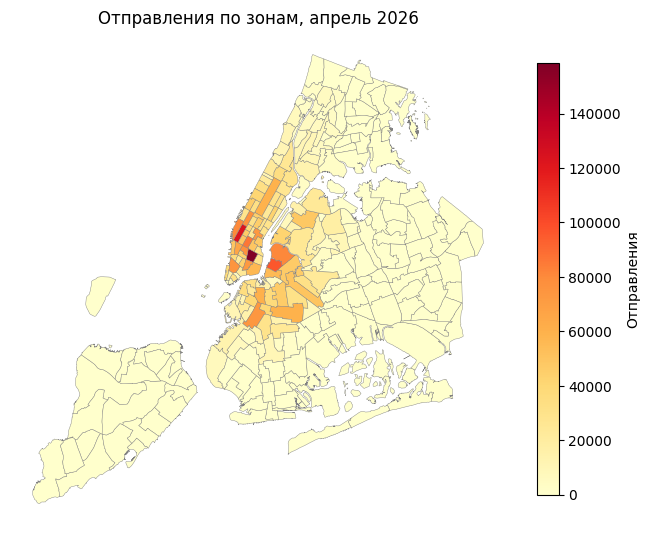

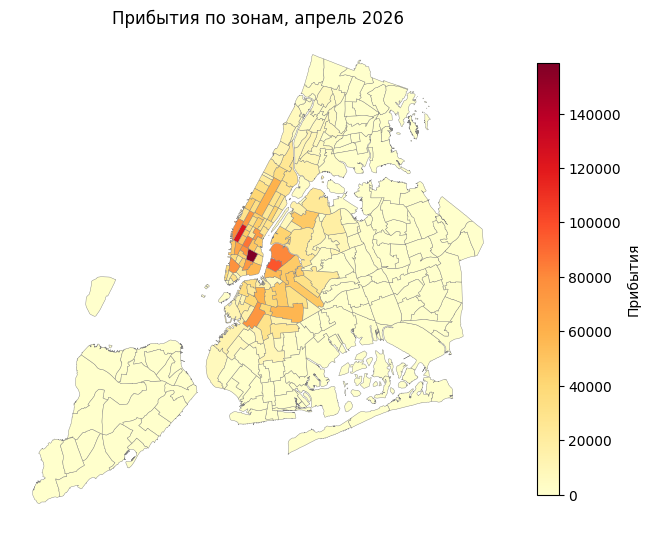

In [5]:
counts = zone_counts.select("zone_id", "starts", "ends").toPandas()
map_data = zones_map.merge(counts, left_on="locationid", right_on="zone_id")
maximum = counts[["starts", "ends"]].max().max()
os.makedirs("output", exist_ok=True)

for column, title in [("starts", "Отправления"), ("ends", "Прибытия")]:
    ax = map_data.plot(
        column=column, cmap="YlOrRd", vmin=0, vmax=maximum,
        legend=True, legend_kwds={"label": title, "shrink": 0.7},
        edgecolor="gray", linewidth=0.3, figsize=(8, 8)
    )
    ax.set_title(f"{title} по зонам, апрель 2026")
    ax.set_axis_off()
    ax.figure.savefig(f"output/{column}_choropleth.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(ax.figure)

spark.catalog.clearCache()